# Streaming decision tree demo

This notebook does what the Assignment 2.2 specification asks of the demo:

1. Load a dataset from a CSV file with the custom I/O pipeline (`numcompute_stream.io`).
2. Split it into chunks to simulate a streaming setting.
3. Train the pipeline incrementally with `.partial_fit()` on each chunk.
4. Log and visualise key metrics over time (accuracy, error, model comparison) with `numcompute_stream.visualise`.

In [3]:
import os, sys
if os.path.basename(os.getcwd()) == "demo":          # run from the repo root or from demo/
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
%matplotlib inline

from numcompute_stream.io import load_table, iter_chunks
from numcompute_stream.preprocessing import Imputer, StandardScaler, OneHotEncoder
from numcompute_stream.pipeline import Pipeline, ColumnTransformer
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.stream import StreamTrainer
from numcompute_stream import visualise as vis

## 1. Load the CSV with the custom I/O pipeline

Task: predict whether a house is in the more expensive half (`price >= median`).

In [4]:
CATEGORICAL = ["mainroad", "guestroom", "basement", "hotwaterheating",
               "airconditioning", "prefarea", "furnishingstatus"]
X, price, feature_names = load_table("Dataset/Housing.csv", target="price", categorical=CATEGORICAL)
y = (price >= np.median(price)).astype(int)

print("X shape:", X.shape)
print("features:", feature_names)
print("class counts:", np.bincount(y))

X shape: (545, 12)
features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']
class counts: [270 275]


## 2. Split into chunks to simulate a stream

The file is sorted by price, so the rows are shuffled once (fixed seed) before chunking.

In [5]:
NUM = [i for i, n in enumerate(feature_names) if n not in CATEGORICAL]
CAT = [i for i, n in enumerate(feature_names) if n in CATEGORICAL]
order = np.random.default_rng(0).permutation(len(y))
X, y = X[order], y[order]

CHUNK = 25
chunks = list(iter_chunks(X, y, CHUNK))
print(len(chunks), "chunks of", CHUNK, "rows")

22 chunks of 25 rows


## 3. Train the pipeline incrementally with `.partial_fit()` on each chunk

Numeric columns are imputed and scaled, categorical columns are one-hot encoded, and the tree buffers rows and
retrains from scratch every time `buffer_size` rows are waiting. Each chunk is passed to `pipe.partial_fit`.

In [6]:
def make_pipeline(buffer_size):
    columns = ColumnTransformer([
        ("num", Pipeline([("impute", Imputer()), ("scale", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(max_categories=4), CAT),
    ])
    return Pipeline([
        ("columns", columns),
        ("tree", DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, buffer_size=buffer_size)),
    ])

pipe = make_pipeline(buffer_size=100)
for i, (X_chunk, y_chunk) in enumerate(chunks):
    pipe.partial_fit(X_chunk, y_chunk)                       # incremental update of every step
    tree = pipe["tree"]
    print(f"chunk {i:2d}: rows seen {tree.n_samples_seen_:3d} | buffered {tree.buffer_fill_:3d} | "
          f"retrains so far {tree.n_retrains_}")

chunk  0: rows seen  25 | buffered  25 | retrains so far 0
chunk  1: rows seen  50 | buffered  50 | retrains so far 0
chunk  2: rows seen  75 | buffered  75 | retrains so far 0
chunk  3: rows seen 100 | buffered   0 | retrains so far 1
chunk  4: rows seen 125 | buffered  25 | retrains so far 1
chunk  5: rows seen 150 | buffered  50 | retrains so far 1
chunk  6: rows seen 175 | buffered  75 | retrains so far 1
chunk  7: rows seen 200 | buffered   0 | retrains so far 2
chunk  8: rows seen 225 | buffered  25 | retrains so far 2
chunk  9: rows seen 250 | buffered  50 | retrains so far 2
chunk 10: rows seen 275 | buffered  75 | retrains so far 2
chunk 11: rows seen 300 | buffered   0 | retrains so far 3
chunk 12: rows seen 325 | buffered  25 | retrains so far 3
chunk 13: rows seen 350 | buffered  50 | retrains so far 3
chunk 14: rows seen 375 | buffered  75 | retrains so far 3
chunk 15: rows seen 400 | buffered   0 | retrains so far 4
chunk 16: rows seen 425 | buffered  25 | retrains so far

## 4. Log key metrics over time

`StreamTrainer` runs the same stream with a fresh pipeline and evaluates it test-then-train: each chunk is
predicted first (rows the model has not seen), then passed to `partial_fit`. Every chunk is logged.

In [7]:
trainer = StreamTrainer(make_pipeline(buffer_size=100), name="buffer=100", verbose=True)
for X_chunk, y_chunk in chunks:
    trainer.step(X_chunk, y_chunk)          # predict the chunk, then partial_fit on it

print(trainer.summary())

[buffer=100] chunk   0 | seen     25 | chunk acc nan | cum acc nan | fit    2.04 ms | retrained False | buffer    25 | mem      6.6 KiB
[buffer=100] chunk   1 | seen     50 | chunk acc nan | cum acc nan | fit    1.22 ms | retrained False | buffer    50 | mem     13.3 KiB
[buffer=100] chunk   2 | seen     75 | chunk acc nan | cum acc nan | fit    2.56 ms | retrained False | buffer    75 | mem     19.9 KiB
[buffer=100] chunk   3 | seen    100 | chunk acc nan | cum acc nan | fit   14.04 ms | retrained True  | buffer     0 | mem      1.5 KiB
[buffer=100] chunk   4 | seen    125 | chunk acc 0.680 | cum acc 0.680 | fit    1.45 ms | retrained False | buffer    25 | mem      8.1 KiB
[buffer=100] chunk   5 | seen    150 | chunk acc 0.760 | cum acc 0.720 | fit    1.26 ms | retrained False | buffer    50 | mem     14.8 KiB
[buffer=100] chunk   6 | seen    175 | chunk acc 0.560 | cum acc 0.667 | fit    1.87 ms | retrained False | buffer    75 | mem     21.4 KiB
[buffer=100] chunk   7 | seen    200

## 5. Visualise metrics over time with `visualise.py`

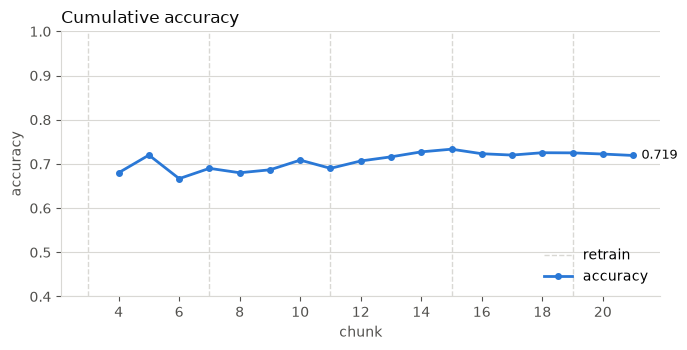

In [8]:
retrains = np.flatnonzero(trainer.history("retrained") > 0)
vis.plot_metric_over_time(trainer.history("cumulative_accuracy"), title="Cumulative accuracy",
                          ylabel="accuracy", retrain_chunks=retrains, ylim=(0.4, 1.0));

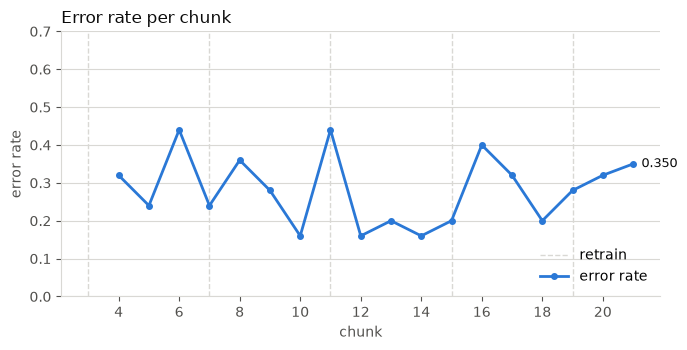

In [9]:
vis.plot_metric_over_time(1 - trainer.history("chunk_accuracy"), title="Error rate per chunk",
                          ylabel="error rate", retrain_chunks=retrains, ylim=(0, 0.7));

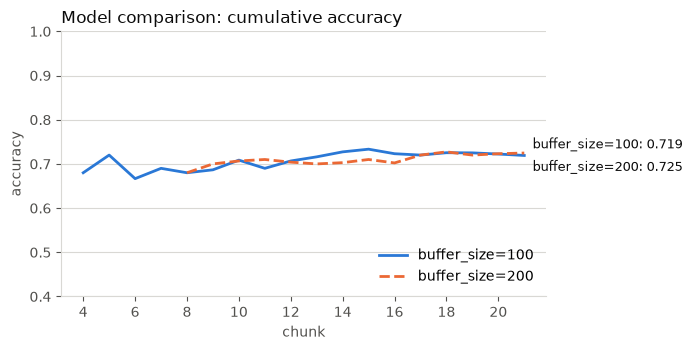

In [10]:
other = StreamTrainer(make_pipeline(buffer_size=200), name="buffer=200")
other.run(iter_chunks(X, y, CHUNK))
vis.compare_models(trainer.history("cumulative_accuracy"), other.history("cumulative_accuracy"),
                   labels=("buffer_size=100", "buffer_size=200"),
                   title="Model comparison: cumulative accuracy", ylim=(0.4, 1.0));

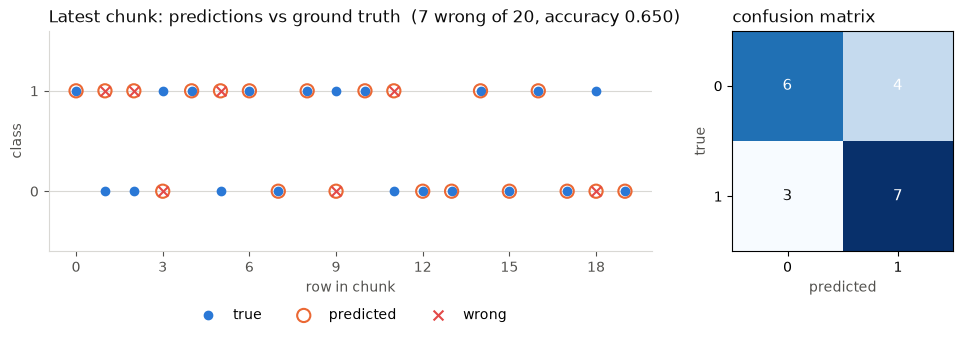

In [11]:
last = trainer.last_chunk_
vis.plot_predictions_vs_ground_truth(last["y_true"], last["y_pred"]);